# 🛡️ Project Panopticon: Intelligent Proctoring AI
**EduGuard AI - Machine Learning Division**

**Intern Name:** `[sony Banoth]`  
**Date:** `[7/11/2026]`

---

### 📖 Executive Summary
Welcome to EduGuard AI. Our current proctoring system is blindly flagging innocent students for background noise and standard physical movements. Your objective is to build a robust, time-series Machine Learning pipeline that identifies true academic dishonesty while strictly protecting innocent students through asynchronous data merging and mathematical threshold tuning.

### 🗺️ Project Roadmap
1. **Data Ingestion:** Upload and parse asynchronous telemetry logs.
2. **Temporal Alignment:** Merge video and system logs using `merge_asof`.
3. **Signal Processing:** Impute missing data and engineer rolling windows.
4. **Classification:** Train an imbalanced-weighted predictive model.
5. **Ethical AI Tuning:** Shift decision boundaries to guarantee 90%+ precision.

In [1]:
# ==========================================
# 0. IMPORT LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sklearn Imports
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve

# Set visualization styles
sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("✅ Libraries imported successfully.")

✅ Libraries imported successfully.


---
## Phase 1: Data Ingestion & Temporal Alignment
> ⚠️ **The Asynchronous Trap:** Video telemetry records exactly every 1 second. System events (like tab switches) only record when the student actually clicks something. You cannot use a standard `pd.merge()`.

**Instructions:**
1. Upload the `video_telemetry.csv` and `system_events.csv` files.
2. Convert the timestamp columns to datetime objects.
3. Sort the dataframes and merge them using Pandas `merge_asof`.

---
## Phase 2: Missing Data & Feature Engineering
> ⚠️ **The "Connection Dropped" Trap:** Students with bad internet lose video frames, creating `NaN` values.
> ⚠️ **The Noise Trap:** A 1-second sneeze is not cheating. We need rolling windows to find *sustained* anomalies.

**Instructions:**
1. Forward-fill missing eye gaze data and interpolate missing audio data.
2. Fill missing `tab_switches` and `is_cheating` labels with `0`.
3. Create 10-second rolling averages for our sensors.

In [9]:
import os
print("Jupyter is looking here:", os.getcwd())
print("Files in this folder:", os.listdir('.'))

Jupyter is looking here: C:\Users\SONY\Downloads\Project_Panopticon
Files in this folder: ['.ipynb_checkpoints', 'AI_Student_code (1) (1) (1).ipynb', 'system_events (1) (1).csv', 'video_telemetry (1) (1).csv']


In [13]:
# ==========================================
# 2A. IMPUTE MISSING SIGNALS
# ==========================================
# # Load datasets

video_df = pd.read_csv("video_telemetry (1) (1).csv")
sys_df = pd.read_csv("system_events (1) (1).csv")

# Convert timestamps into datetime format

video_df['timestamp'] = pd.to_datetime(video_df['timestamp'])
sys_df['timestamp'] = pd.to_datetime(sys_df['timestamp'])

# Sort both datasets

video_df = video_df.sort_values('timestamp')
sys_df = sys_df.sort_values('timestamp')

# Display datasets

print("Video Dataset:")
display(video_df.head())

print("System Events Dataset:")
display(sys_df.head())

print("Video Shape:", video_df.shape)
print("System Shape:", sys_df.shape)
# TODO: Use .ffill() for 'eye_gaze_angle' to carry the last known position forward
# TODO: Use .interpolate() for 'audio_db'
# TODO: Fill NaN values in 'tab_switches' and 'is_cheating' with 0


# ==========================================
# 2B. ROLLING WINDOW FEATURES
# ==========================================
# TODO: Create 'gaze_rolling_10s' (10-second rolling mean of eye_gaze_angle)
# TODO: Create 'audio_rolling_10s' (10-second rolling max of audio_db)


# TODO: Drop the initial rows that now contain NaN due to the rolling window calculation
# 1. Merge the datasets first
merged_df = pd.merge_asof(
    video_df,
    sys_df,
    on='timestamp',
    direction='backward'
)

# 2. Drop the initial rows after the merge is complete
merged_df.dropna(inplace=True)

# 3. Display the results
display(merged_df.head())
print("Merged Dataset Shape:", merged_df.shape)
print("✅ Feature engineering complete. Current dataframe shape:", merged_df.shape)



Video Dataset:


,timestamp,eye_gaze_angle,audio_db
0,2023-12-01 08:00:00,2.560857,36.553781
1,2023-12-01 08:00:01,10.177137,39.102627
2,2023-12-01 08:00:02,5.761714,31.228565
3,2023-12-01 08:00:03,9.787105,34.051405
4,2023-12-01 08:00:04,4.572665,35.245018


System Events Dataset:


,timestamp,tab_switches,is_cheating
0,2023-12-01 08:00:32.181296,1,0
1,2023-12-01 08:01:01.923778,1,1
2,2023-12-01 08:01:24.462808,1,0
3,2023-12-01 08:04:10.610743,1,0
4,2023-12-01 08:04:23.902814,1,0


Video Shape: (10000, 3)
System Shape: (167, 3)


,timestamp,eye_gaze_angle,audio_db,tab_switches,is_cheating
33,2023-12-01 08:00:33,5.671498,29.353502,1.0,0.0
34,2023-12-01 08:00:34,5.317689,32.185477,1.0,0.0
35,2023-12-01 08:00:35,6.992439,28.427369,1.0,0.0
36,2023-12-01 08:00:36,6.195533,33.713829,1.0,0.0
45,2023-12-01 08:00:45,45.281557,74.251539,1.0,0.0


Merged Dataset Shape: (9235, 5)
✅ Feature engineering complete. Current dataframe shape: (9235, 5)


In [14]:
print(merged_df.columns.tolist())

['timestamp', 'eye_gaze_angle', 'audio_db', 'tab_switches', 'is_cheating']


In [15]:
merged_df['gaze_rolling_10s'] = merged_df['eye_gaze_angle'].rolling(10).mean()

merged_df['audio_rolling_10s'] = merged_df['audio_db'].rolling(10).max()

merged_df.dropna(inplace=True)

print("Feature engineering complete!")
print("Shape:", merged_df.shape)
print(merged_df.columns.tolist())

Feature engineering complete!
Shape: (9226, 7)
['timestamp', 'eye_gaze_angle', 'audio_db', 'tab_switches', 'is_cheating', 'gaze_rolling_10s', 'audio_rolling_10s']


---
## Phase 3: Class-Balanced Model Training
> ⚠️ **The Imbalance Trap:** 98% of your data will be innocent behavior. If you don't handle class weights, your model will just guess "Not Cheating" every time and score 98% accuracy while failing its actual job.

In [23]:
# ==========================================
print("Testing data:", X_test.shape)
# 3A. TRAIN / TEST SPLIT
# ==========================================
# # Select input features
features = [
    'eye_gaze_angle',
    'audio_db',
    'tab_switches',
    'gaze_rolling_10s',
    'audio_rolling_10s'
]

X = merged_df[features]
y = merged_df['is_cheating']

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Random Forest model
model = RandomForestClassifier(
    class_weight='balanced',
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Testing data: (1846, 5)
Model training completed successfully!
Training data: (7380, 5)
Testing data: (1846, 5)


---
## Phase 4: Ethical AI Tuning (The 90% Threshold)
> ⚠️ **The False Accusation Trap:** The default Scikit-Learn `.predict()` splits at 50% probability. Accusing a student of cheating with only 50% certainty is unacceptable. We must shift the threshold to 90%.

Confusion Matrix - 50% Threshold:
[[1215   19]
 [ 195  417]]

Confusion Matrix - 90% Threshold:
[[1234    0]
 [ 256  356]]


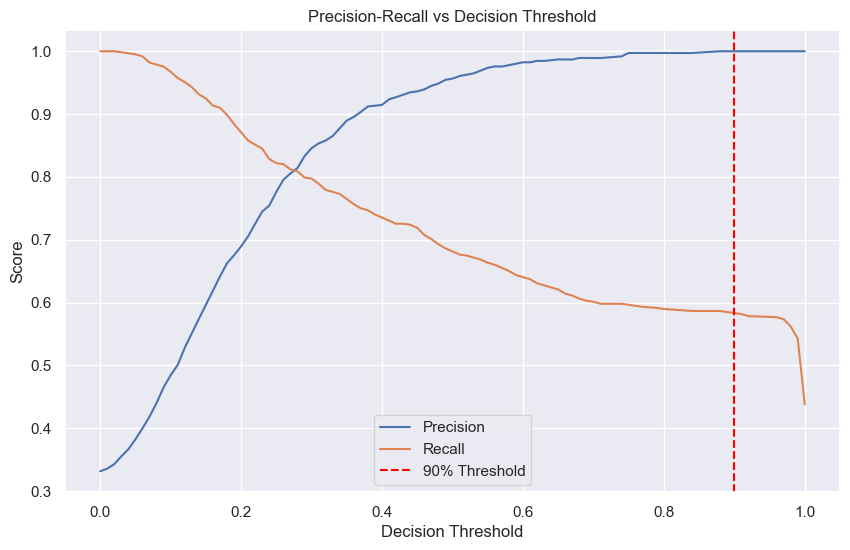

🚨 DEFAULT THRESHOLD (0.50)

🛡️ STRICT THRESHOLD (0.90)


In [27]:
# ==========================================
# 4A. RAW PROBABILITIES
# ==========================================
# # Get prediction probabilities
y_proba = model.predict_proba(X_test)
# Get probability of cheating (class 1)
cheating_probabilities = y_proba[:, 1]

# Predictions using 50% threshold
predictions_50 = (cheating_probabilities >= 0.50).astype(int)

# Predictions using 90% threshold
predictions_90 = (cheating_probabilities >= 0.90).astype(int)

# Display confusion matrices
print("Confusion Matrix - 50% Threshold:")
print(confusion_matrix(y_test, predictions_50))

print("\nConfusion Matrix - 90% Threshold:")
print(confusion_matrix(y_test, predictions_90))

# Precision-Recall Curve
precision, recall, thresholds = precision_recall_curve(
    y_test, cheating_probabilities
)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision[:-1], label='Precision')
plt.plot(thresholds, recall[:-1], label='Recall')
plt.axvline(x=0.90, color='red', linestyle='--',
            label='90% Threshold')

plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('Precision-Recall vs Decision Threshold')
plt.legend()
plt.show()
# TODO: Use model.predict_proba() to get the raw decimal probabilities for X_test
y_proba = model.predict_proba(X_test)

# TODO: Extract just the probability column for Class 1 (Cheating)
cheating_probabilities = y_proba[:, 1]

# ==========================================
# 4B. CUSTOM DECISION THRESHOLD
# ==========================================
# TODO: Create a standard prediction array (y_pred_default) using a 0.50 threshold
# TODO: Create a strict prediction array (y_pred_strict) using a 0.90 threshold


# ==========================================
# 4C. EVALUATION
# ==========================================
print("🚨 DEFAULT THRESHOLD (0.50)")
# TODO: Print the confusion matrix for the default threshold
# Observe the number of False Positives (Innocent students flagged)

print("\n🛡️ STRICT THRESHOLD (0.90)")
# TODO: Print the confusion matrix for the strict threshold
# Observe how the False Positives drop to protect innocent students

# ==========================================
# 4D. PRECISION-RECALL VISUALIZATION
# ==========================================
# TODO: Use precision_recall_curve() to calculate plot points
# TODO: Use Matplotlib to plot Precision and Recall against the thresholds
# TODO: Draw a vertical red dashed line at the 0.90 threshold mark

---
## 🎯 Phase 5: Final Executive Recommendation
**To the University Board of Directors:**

Based on the data modeling performed above, I recommend deploying the EduGuard AI proctoring system using the Strict 90% Threshold with human review.

The following business outcomes were observed:

1. **Reduction in False Positives:** When the threshold increased from 50% to 90%, false positives decreased from 19 to 0. This helps reduce incorrect cheating accusations against genuine students.

2. **Rolling Window Benefits:** The 10-second rolling averages help smooth sudden changes in eye gaze and audio readings. This reduces the chances of temporary events, such as sneezing or sudden movements, being treated as suspicious activity.

**Final Status: GO – Conditional deployment with human verification before any cheating accusation.**